In [90]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import math

Read the data

In [91]:
iris = pd.read_csv('iris.csv')

In [92]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [93]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [94]:
iris['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

spilt the data into training and testing 

In [95]:
from sklearn.model_selection import train_test_split

In [96]:
x = iris.iloc[:, :4]
y = iris.iloc[:, 4]

In [97]:
x.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [98]:
y.head()

0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object

In [99]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, )

In [100]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

Build the model C5.0

In [101]:
from sklearn.tree import DecisionTreeClassifier

In [102]:
clf = DecisionTreeClassifier(max_depth=3, max_leaf_nodes=10, criterion='entropy')

In [103]:
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, max_leaf_nodes=10)

Predict and get the training and testing metrics 

In [104]:
yhat_train = clf.predict(x_train)

In [105]:
from sklearn.metrics import confusion_matrix, classification_report

In [106]:
cs= confusion_matrix(y_train, yhat_train)
cs

array([[41,  0,  0],
       [ 0, 39,  3],
       [ 0,  1, 36]])

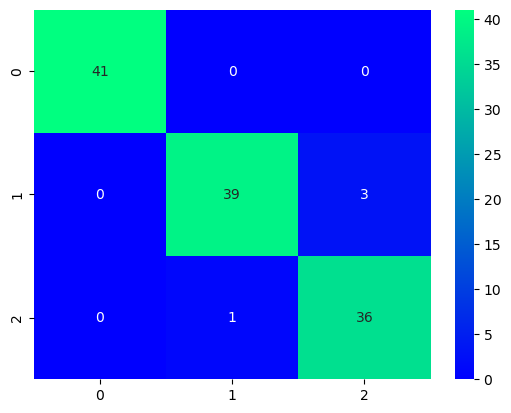

In [107]:
sns.heatmap(cs , annot=True , cmap='winter')
plt.show()

In [108]:
print(classification_report(y_train, yhat_train))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        41
  versicolor       0.97      0.93      0.95        42
   virginica       0.92      0.97      0.95        37

    accuracy                           0.97       120
   macro avg       0.97      0.97      0.97       120
weighted avg       0.97      0.97      0.97       120



In [109]:
yhat_test = clf.predict(x_test)

In [110]:
cm = confusion_matrix(y_test, yhat_test)

In [111]:
cm 

array([[ 9,  0,  0],
       [ 0,  8,  0],
       [ 0,  0, 13]])

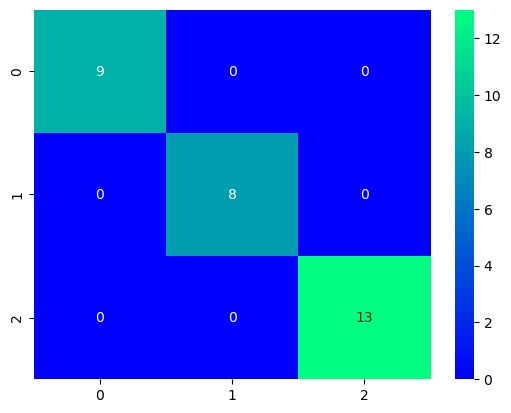

In [112]:
sns.heatmap(cm , annot=True , cmap='winter')
plt.show()

In [113]:
print(classification_report(y_test, yhat_test))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       1.00      1.00      1.00         8
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [114]:
clf = DecisionTreeClassifier(max_depth=0, max_leaf_nodes=10, criterion='gini')

In [ ]:
## complete this 
